**Post Test 6 - Self-Organizing Maps**


*Self-organizing maps* (SOM), atau yang disebut juga dengan topology-preserving maps, adalah algoritma klasterisasi (clustering) yang termasuk dalam unsupervised learning.


# Kode (Jangan diubah)
Fungsi *self-organizing maps* sesuai kode praktikum pada modul.


In [ ]:
import numpy as np

def som(X, lrate, b, max_epoch, n_cluster):
    centroids = np.random.uniform(size=(n_cluster, len(X[0])))
    epoch = 0
    labels = []
    while epoch < max_epoch:
        for x in X:
            d = [sum((w - x) ** 2) for w in centroids]
            min = np.argmin(d)
            centroids[min] += lrate * (x - centroids[min])
        lrate *= b
        epoch += 1

    for x in X:
        d = [sum((w - x) ** 2) for w in centroids]
        min = np.argmin(d)
        labels.append(min)
    return centroids, labels

def draw(X, target, centroids):
    colors = 'rgbcmyk'
    for x, label in zip(X, target):
        plt.plot(x[0], x[1], colors[label] + '.')
    plt.plot(centroids[:, 0], centroids[:, 1], 'kx')

# Soal


Gunakan dataset **Pola_Kunjungan_Perpustakaan.csv** yang telah dilampirkan.


Terdapat data sintetis 90 pengunjung perpustakaan yang berisi `ID_Pengunjung`, `Kunjungan_per_Bulan`, dan `Rata_Durasi_Menit`. Pada data tersebut, akan dilakukan klasterisasi berdasarkan jumlah kunjungan per bulan dan rata-rata durasi setiap kunjungan menjadi **3 klaster** dengan:
1. learning rate = 0.5, b = 0.5, dan max_epoch = 6.

Lengkapi bagian kode yang ditandai untuk diisi praktikan. Letakkan CSV di folder yang sama dengan notebook. ID pengunjung tidak digunakan sebagai fitur.


### a) Load data


In [ ]:
import pandas as pd

data = pd.read_csv('Pola_Kunjungan_Perpustakaan.csv')
data.head()


,ID_Pengunjung,Kunjungan_per_Bulan,Rata_Durasi_Menit
0,P001,5,238
1,P002,8,112
2,P003,5,49
3,P004,21,82
4,P005,3,42


### b) Preprocess


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Memuat data secara langsung untuk mencegah NameError
data = pd.read_csv('Pola_Kunjungan_Perpustakaan.csv')

# Diisi praktikan: pilih dua fitur sesuai soal, tanpa ID pengunjung.
fitur = ['Kunjungan_per_Bulan', 'Rata_Durasi_Menit']
scaler = MinMaxScaler()
X = scaler.fit_transform(data[fitur])
print('Data setelah normalisasi:\n', X)

Data setelah normalisasi:
 [[0.2        0.90794979]
 [0.35       0.38075314]
 [0.2        0.11715481]
 [1.         0.25523013]
 [0.1        0.08786611]
 [0.05       0.73640167]
 [0.35       0.84518828]
 [0.15       0.72803347]
 [0.55       0.10460251]
 [0.65       0.24267782]
 [0.05       0.13807531]
 [0.75       0.20083682]
 [0.1        0.0292887 ]
 [0.2        0.07112971]
 [0.75       0.20502092]
 [0.1        0.55648536]
 [0.7        0.19246862]
 [0.75       0.13807531]
 [0.1        0.75732218]
 [0.6        0.10041841]
 [0.55       0.23012552]
 [0.1        0.08368201]
 [0.25       0.05857741]
 [0.1        0.09205021]
 [0.1        1.        ]
 [0.1        0.0334728 ]
 [0.9        0.22175732]
 [0.15       0.65271967]
 [0.2        0.66945607]
 [0.1        0.0251046 ]
 [0.45       0.0376569 ]
 [0.75       0.18410042]
 [0.7        0.27196653]
 [0.25       0.78242678]
 [0.6        0.22175732]
 [0.05       0.54811715]
 [0.5        0.08786611]
 [0.1        0.55648536]
 [0.15       0.0251046 

### c) Klasterisasi


Centroid terbaru:
 [[0.21252659 0.68760909]
 [0.67672647 0.17420834]
 [0.09992304 0.08119171]]
Silhouette score: 0.6859452768958534


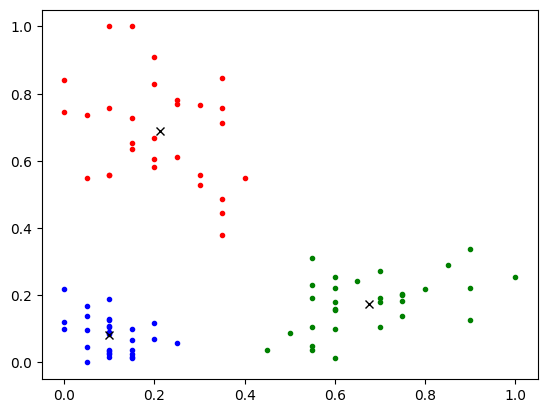

In [ ]:
import numpy as np
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

def som(X, lrate, b, max_epoch, n_cluster):
    centroids = np.random.uniform(size=(n_cluster, len(X[0])))
    epoch = 0
    labels = []
    while epoch < max_epoch:
        for x in X:
            d = [sum((w - x) ** 2) for w in centroids]
            min = np.argmin(d)
            centroids[min] += lrate * (x - centroids[min])
        lrate *= b
        epoch += 1

    for x in X:
        d = [sum((w - x) ** 2) for w in centroids]
        min = np.argmin(d)
        labels.append(min)
    return centroids, labels

def draw(X, target, centroids):
    colors = 'rgbcmyk'
    for x, label in zip(X, target):
        plt.plot(x[0], x[1], colors[label] + '.')
    plt.plot(centroids[:, 0], centroids[:, 1], 'kx')

# X adalah hasil normalisasi fitur Kunjungan_per_Bulan dan Rata_Durasi_Menit.
np.random.seed(42)
centroids, labels = som(X, lrate=0.5, b=0.5, max_epoch=6, n_cluster=3)
print('Centroid terbaru:\n', centroids)

silhouette = silhouette_score(X, labels)
print('Silhouette score:', silhouette)
draw(X, labels, centroids)

Perbandingan Klasterisasi


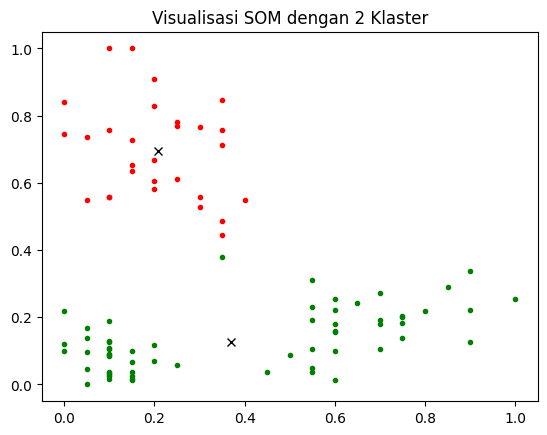

=== Jumlah Klaster: 2 ===
Centroid terbaru:
 [[0.2084621  0.69607617]
 [0.37044529 0.12670138]]
Silhouette score: 0.5047090619695475
Centroid dalam satuan asli:
 [[  5.16924194 187.36220377]
 [  8.40890587  51.28162897]]




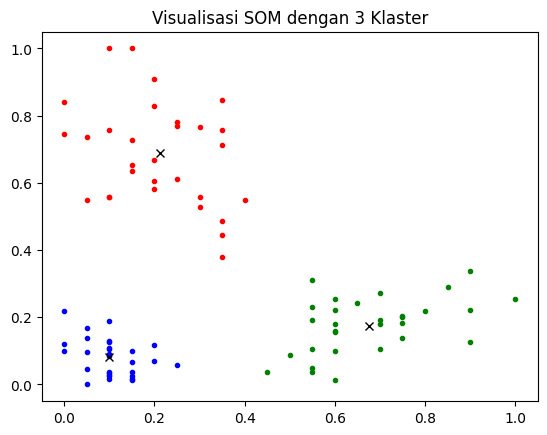

=== Jumlah Klaster: 3 ===
Centroid terbaru:
 [[0.21252659 0.68760909]
 [0.67672647 0.17420834]
 [0.09992304 0.08119171]]
Silhouette score: 0.6859452768958534
Centroid dalam satuan asli:
 [[  5.25053171 185.33857176]
 [ 14.53452944  62.63579435]
 [  2.99846071  40.40481903]]




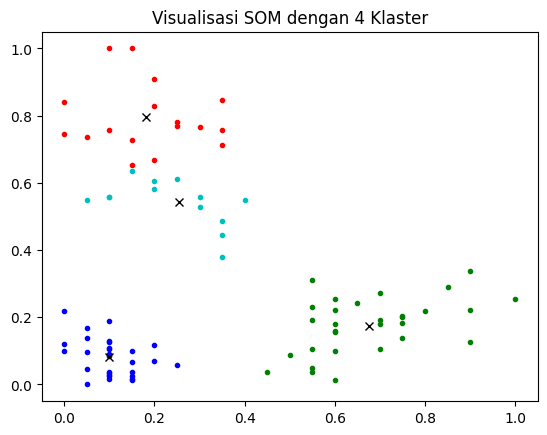

=== Jumlah Klaster: 4 ===
Centroid terbaru:
 [[0.18143859 0.79608449]
 [0.67672647 0.17420834]
 [0.0999029  0.08116847]
 [0.25535539 0.54378358]]
Silhouette score: 0.5929096603130478
Centroid dalam satuan asli:
 [[  4.62877178 211.26419366]
 [ 14.53452944  62.63579435]
 [  2.99805801  40.39926342]
 [  6.10710786 150.964275  ]]




,Jumlah Klaster,Silhouette Score
0,2,0.504709
1,3,0.685945
2,4,0.592910


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

def som(X, lrate, b, max_epoch, n_cluster):
    centroids = np.random.uniform(size=(n_cluster, len(X[0])))
    epoch = 0
    labels = []
    while epoch < max_epoch:
        for x in X:
            d = [sum((w - x) ** 2) for w in centroids]
            min = np.argmin(d)
            centroids[min] += lrate * (x - centroids[min])
        lrate *= b
        epoch += 1

    for x in X:
        d = [sum((w - x) ** 2) for w in centroids]
        min = np.argmin(d)
        labels.append(min)
    return centroids, labels

def draw(X, target, centroids):
    colors = 'rgbcmyk'
    for x, label in zip(X, target):
        plt.plot(x[0], x[1], colors[label] + '.')
    plt.plot(centroids[:, 0], centroids[:, 1], 'kx')

results = []
clusters_to_test = [2, 3, 4]

for k in clusters_to_test:
    np.random.seed(42)
    centroids, labels = som(X, lrate=0.5, b=0.5, max_epoch=6, n_cluster=k)
    try:
        sh_score = silhouette_score(X, labels)
    except Exception as e:
        sh_score = None

    results.append({
        'Jumlah Klaster': k,
        'Silhouette Score': sh_score,
        'Centroid Asli': scaler.inverse_transform(centroids).tolist()
    })

    plt.figure()
    draw(X, labels, centroids)
    plt.title(f'Visualisasi SOM dengan {k} Klaster')
    plt.show()

    print(f'=== Jumlah Klaster: {k} ===')
    print('Centroid terbaru:\n', centroids)
    print('Silhouette score:', sh_score)
    print('Centroid dalam satuan asli:\n', scaler.inverse_transform(centroids))
    print('\n')

# Diisi praktikan: buat tabel perbandingan silhouette score dari setiap percobaan.
df_comparison = pd.DataFrame([
    {'Jumlah Klaster': r['Jumlah Klaster'], 'Silhouette Score': r['Silhouette Score']}
    for r in results
])
display(df_comparison)

Kita menggunakan **silhouette score** untuk menilai hasil clustering. Nilainya berkisar antara -1 hingga 1:

- Mendekati 1: klaster relatif kompak dan terpisah dengan baik.
- Mendekati 0: klaster berdekatan atau tumpang tindih.
- Negatif: sebagian data lebih dekat ke klaster lain daripada klasternya sendiri.

Silhouette bukan akurasi dan tidak harus mencapai 1. Jika suatu percobaan hanya menghasilkan satu klaster aktif, silhouette tidak dapat dihitung; laporkan kondisi tersebut.


Pertanyaan

1. Apakah 3 klaster merupakan pilihan yang paling sesuai untuk data tersebut? Lakukan percobaan dengan 2, 3, dan 4 klaster, dengan learning rate, b, dan max_epoch tetap seperti percobaan awal. Tampilkan tabel perbandingan silhouette score, lalu tentukan jumlah klaster yang paling sesuai berdasarkan hasil percobaan.

2. Berdasarkan hasil klasterisasi yang dipilih, jelaskan karakteristik pengunjung pada setiap klaster menggunakan grafik dan nilai centroid dalam satuan asli. Apakah jumlah klaster yang lebih banyak selalu menghasilkan pengelompokan yang lebih baik? Dukung jawabanmu dengan hasil percobaan.

Jawaban:

1. Ya, berdasarkan hasil percobaan yang telah dijalankan, 3 klaster merupakan pilihan yang paling sesuai untuk data tersebut. Hal ini ditunjukkan oleh nilai silhouette score pada masing-masing percobaan, di mana 2 klaster menghasilkan nilai sekitar 0.5047, 3 klaster menghasilkan nilai tertinggi yaitu sekitar 0.6859, dan 4 klaster menghasilkan nilai sekitar 0.5929. Karena nilai silhouette score untuk 3 klaster paling mendekati angka 1 dibandingkan yang lain, maka struktur pengelompokan dengan 3 klaster adalah yang paling optimal dan terpisah dengan baik.

2. Karakteristik pengunjung berdasarkan model terbaik dengan 3 klaster dapat dianalisis dari nilai centroid dalam satuan asli sebagai berikut:

Klaster pertama memiliki centroid kunjungan per bulan sekitar 5.25 kali dan rata-rata durasi sekitar 185.34 menit. Kelompok ini merepresentasikan tipe pengunjung yang jarang berkunjung namun menghabiskan waktu sangat lama di perpustakaan setiap kali datang.

Klaster kedua memiliki centroid kunjungan per bulan sekitar 14.53 kali dan rata-rata durasi sekitar 62.64 menit. Kelompok ini merepresentasikan tipe pengunjung yang sangat aktif berkunjung dengan durasi kunjungan sedang.

Klaster ketiga memiliki centroid kunjungan per bulan sekitar 3.00 kali dan rata-rata durasi sekitar 40.40 menit. Kelompok ini merepresentasikan tipe pengunjung yang jarang berkunjung dengan durasi kunjungan yang juga singkat.

Berdasarkan hasil pengujian ini, jumlah klaster yang lebih banyak tidak selalu menghasilkan pengelompokan yang lebih baik. Hal ini terbukti ketika jumlah klaster dinaikkan dari 3 menjadi 4, nilai silhouette score justru mengalami penurunan dari 0.6859 menjadi 0.5929. Penurunan ini menandakan bahwa penambahan klaster baru membuat batas antar-kelompok menjadi lebih tumpang tindih dan kurang terdefinisi secara jelas.

In [17]:
import pandas as pd

# Membuat tabel perbandingan silhouette score berdasarkan hasil percobaan
data_perbandingan = {
    'Jumlah Klaster': [2, 3, 4],
    'Silhouette Score': [0.504709, 0.685945, 0.592910]
}

df_hasil = pd.DataFrame(data_perbandingan)
print("=== TABEL PERBANDINGAN SILHOUETTE SCORE ===")
display(df_hasil)

=== TABEL PERBANDINGAN SILHOUETTE SCORE ===


,Jumlah Klaster,Silhouette Score
0,2,0.504709
1,3,0.685945
2,4,0.592910
